# 02 · Mean word frequency

**Do openings that use more familiar words win more often?** Use the same published training pairs, Minimal cleaning, randomized A/B assignments, and three discussion-grouped folds as the [Flesch notebook](../readability/flesch_reading_ease.ipynb).

For each opening, average the Zipf frequencies of the tokens with a positive score in wordfreq's large English wordlist. Repeated words count each time they occur. A lookup returning zero counts toward the **unlisted share** and stays out of the mean. A reply with no scored tokens has a missing mean. Zipf frequency is a logarithmic measure of how common a word is in the reference data. Names, niche terminology, spelling variants, and other languages can affect coverage. Common function words can raise the mean without making the reasoning easier to follow. [wordfreq documentation](https://github.com/rspeer/wordfreq#usage)

The [standalone script](analyze_word_frequency.py) saves timestamped runs. Install `wordfreq==3.1.1` in the active kernel to regenerate a run.

In [1]:
import json
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "team-setup").is_dir() and (p / "pyproject.toml").is_file()
)
RUNS = REPO / "project/data/processed/linguistic-features/word-frequency"
SCRIPT = REPO / "project/notebooks/linguistic-features/lexical-complexity/analyze_word_frequency.py"
RUN_ID = None
runs = sorted(RUNS.glob("*/results.json"))
if RUN_ID is None and not runs:
    subprocess.run([sys.executable, str(SCRIPT)], check=True)
    runs = sorted(RUNS.glob("*/results.json"))
report_path = RUNS / RUN_ID / "results.json" if RUN_ID else runs[-1]
report = json.loads(report_path.read_text())
pairs = pd.read_parquet(report_path.parent / "paired_scores.parquet")
openings = pd.read_parquet(report_path.parent / "opening_scores.parquet")
print(f"{len(pairs):,} complete pairs · {len(openings):,} unique openings · {report['discussions']:,} discussions")
print(f"{report['listed_token_share']:.2%} of token occurrences received a reference score.")
print(f"{report['shared_pairs'] - len(pairs):,} shared pairs excluded for missing frequency scores.")

3,451 complete pairs · 6,581 unique openings · 2,507 discussions
99.87% of token occurrences received a reference score.
0 shared pairs excluded for missing frequency scores.


## Score distribution and unlisted words

Summarize each distinct opening once. The outlier table shows two example openings at each extreme of the mean and the unlisted share. Unlisted examples indicate gaps in the reference lookup.

In [2]:
feature = "mean_zipf_frequency"
display(openings[[feature, "tokens", "unlisted_share"]].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).round(3))
outlier_ids = pd.Index([
    *openings.nsmallest(2, feature).index,
    *openings.nlargest(2, feature).index,
    *openings.nlargest(2, "unlisted_share").index,
]).unique()
display(openings.loc[outlier_ids, [
    feature, "tokens", "unlisted_share", "unlisted_examples", "opening_preview",
]].round(3))

,mean_zipf_frequency,tokens,unlisted_share
count,6581.000,6581.000,6581.000
mean,5.906,234.739,0.001
std,0.134,193.381,0.004
min,4.891,40.000,0.000
1%,5.546,51.000,0.000
25%,5.824,107.000,0.000
50%,5.911,176.000,0.000
75%,5.997,296.000,0.000
99%,6.188,987.400,0.019
max,6.327,1724.000,0.126


,mean_zipf_frequency,tokens,unlisted_share,unlisted_examples,opening_preview
comment_id,,,,,
t1_cabbfp2,4.891,222,0.126,"melonzz, swayinthemorning, nerifrån, ibertyordeath, kanyepajamas, meanmerging","Here is a list of video links collected from comments that redditors have made in response to this submission: |Source Comment|Score|Video Link| |:-------|:-------|:-------| |melonzz|10|Jedi Mind Tricks - ""I Against I"" feat. Planetary of Ou"
t1_ci1i9ou,5.208,248,0.004,roshonara,"Anwar al-Awlaki was one of the english language mouthpieces of al qaeda. inciting Nawaf al-Hazmi and Khalid al-Mihdhar,to hijack American Airlines Flight 77 Serving as the vice president of a charity the FBI determined funded terrorism In 2"
t1_cmzx0i4,6.327,95,0.000,,"Do you think that the fact that most of these men and women expressing these views are young comes into play? I think most Redditors are between 14-25 and that is the age where all you want to do is have fun, so the idea of having a child i"
t1_cptlz3s,6.321,67,0.000,,"Actually this isn't correct. If you have a mixture of women and men, you should include all of the women that need it down to pee, all of the times they need it down to poop and all of the times the men need it down to poop. If you do so yo"
t1_chzwhlt,5.903,67,0.060,"isan't, ruller, moght, unnotice","Everyone has held a banana in their hands, so you get an idea by making it relative to your own hand. Not being uniform generally isan't a problem since its just an approximation. The curve works to give an idea how the banana is oriented o"


## Paired association and standalone prediction

The association table reports how often the winner had the higher mean Zipf score among unequal scores. Ties are separate. The intervals resample whole OP discussions. The close-length check keeps pairs within 50 words of each other, using the same word counts as the earlier length analysis.

The classifier predicts whether A wins from `mean_zipf_A − mean_zipf_B`. Scaling is fitted within each training fold. ROC-AUC is the primary predictive metric. Average precision is interpreted relative to the A-wins prevalence. The Spearman correlation with word count uses each distinct analyzed opening once. These checks describe the signal within published pairs.

In [3]:
metrics = pd.DataFrame({
    "All pairs": report["winner_higher"], "Within 50 words": report["within_50_words"],
}).T
metrics["winner_higher_pct"] = 100 * metrics["winner_higher_rate"].astype(float)
metrics["CI lower_pct"] = metrics["ci_95"].map(lambda interval: 100 * interval[0])
metrics["CI upper_pct"] = metrics["ci_95"].map(lambda interval: 100 * interval[1])
display(metrics[[
    "pairs", "winner_higher", "winner_lower", "ties",
    "winner_higher_pct", "CI lower_pct", "CI upper_pct",
]].infer_objects().round(3))
display(pd.Series({
    "ROC-AUC": report["prediction"]["roc_auc"],
    "Average precision": report["prediction"]["average_precision"],
    "A-wins prevalence": report["prediction"]["a_win_prevalence"],
    "Spearman vs word count": report["spearman_with_word_count"],
}, name="value").round(4).to_frame())

,pairs,winner_higher,winner_lower,ties,winner_higher_pct,CI lower_pct,CI upper_pct
All pairs,3451,1513,1937,1,43.855,42.104,45.553
Within 50 words,1144,522,621,1,45.669,42.805,48.587


,value
ROC-AUC,0.5735
Average precision,0.5643
A-wins prevalence,0.4967
Spearman vs word count,-0.0305


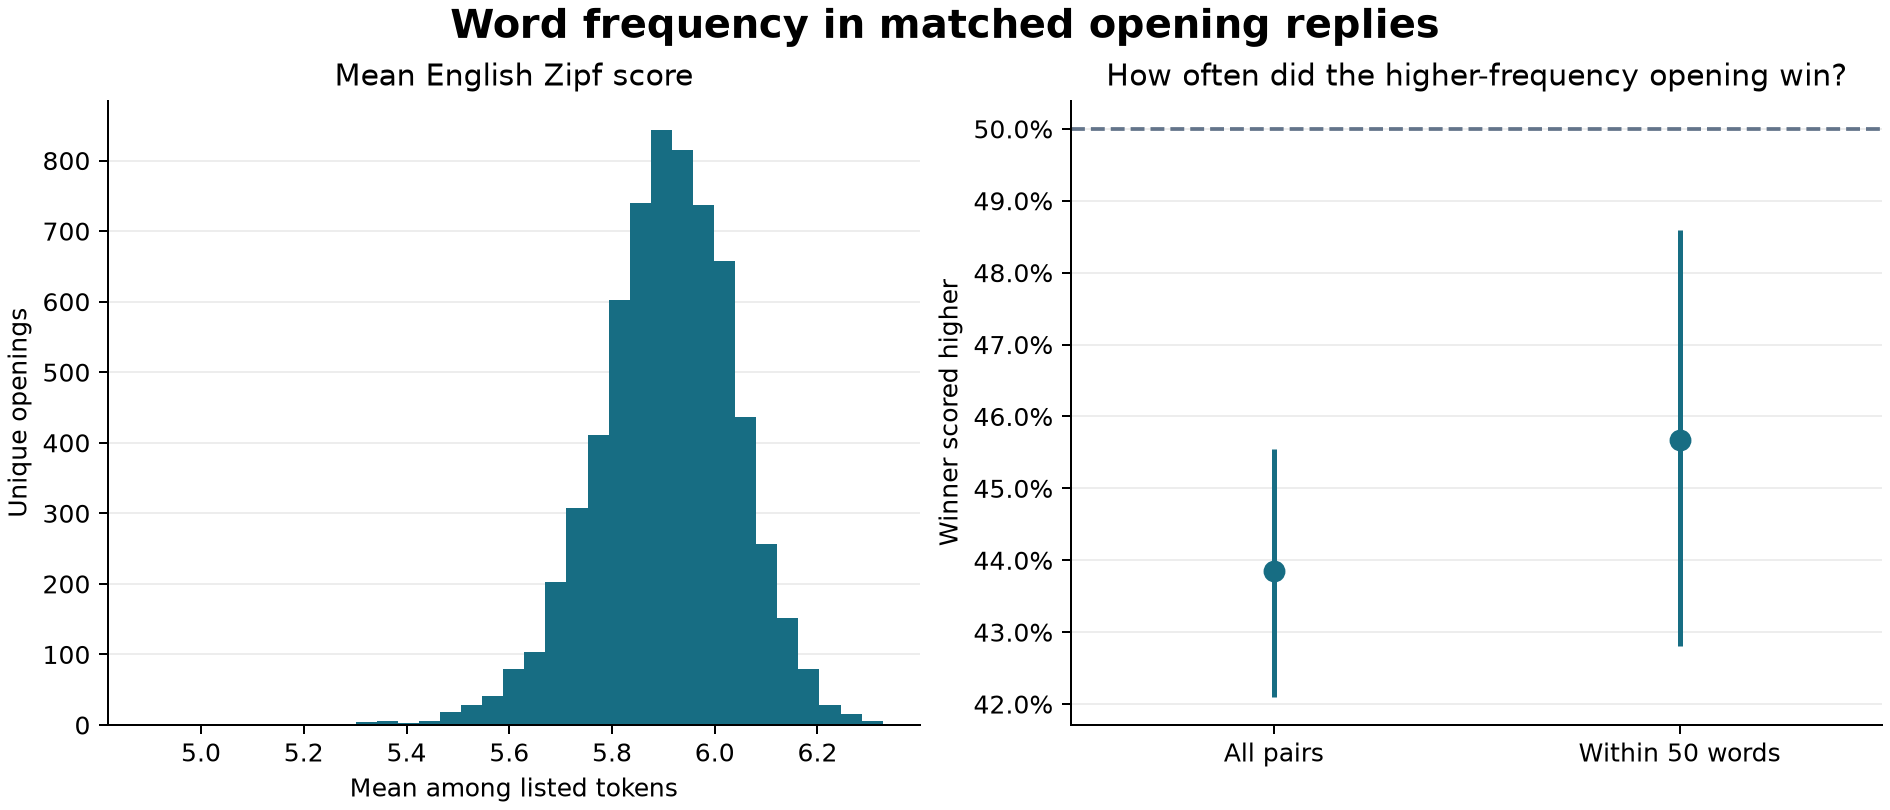

In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, (distribution, paired_plot) = plt.subplots(1, 2, figsize=(10.5, 4.5), layout="constrained")
fig.suptitle("Word frequency in matched opening replies", weight="bold", fontsize=16)
distribution.hist(openings[feature], bins=35, color="#176d83")
distribution.set(title="Mean English Zipf score", xlabel="Mean among listed tokens", ylabel="Unique openings")
x = np.arange(len(metrics))
paired_plot.axhline(50, linestyle="--", color="#63748a")
paired_plot.vlines(x, metrics["CI lower_pct"], metrics["CI upper_pct"], color="#176d83", lw=2)
paired_plot.scatter(x, metrics["winner_higher_pct"], color="#176d83", s=60, zorder=3)
paired_plot.set_xticks(x, metrics.index.tolist())
paired_plot.set(title="How often did the higher-frequency opening win?",
                ylabel="Winner scored higher", xlim=(-0.5, len(x) - 0.5))
paired_plot.yaxis.set_major_formatter(PercentFormatter(100))
for ax in (distribution, paired_plot):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.22)
    ax.set_axisbelow(True)
fig.savefig(report_path.parent / "word_frequency_comparison.png", dpi=180, facecolor="white")
plt.show()

## Sensitivity to function words

The primary analysis above uses **all token occurrences**. This check recomputes it on the same complete pairs as both alternatives, so any change in performance comes from the token rule rather than a change in the comparison sample.

| Rule | Tokens kept |
| --- | --- |
| All words | Every word occurrence in the Minimal-cleaned opening. |
| Content words | Occurrences tagged as nouns, verbs, adjectives, or adverbs by NLTK's English part-of-speech tagger. |
| No stopwords | Occurrences outside scikit-learn's fixed English stopword list. |

All three means average tokens with a listed Zipf score. Both alternatives retain repetitions. Part-of-speech errors can be more likely in fragments and informal writing. The stopword list applies the same rule regardless of context. A signal that persists after filtering can still reflect differences in topic or terminology. [NLTK tagging documentation](https://www.nltk.org/api/nltk.tag.pos_tag.html)

The [standalone sensitivity script](analyze_word_frequency_sensitivity.py) saves runs separately. To regenerate, use the wordfreq dependency above and install `nltk==3.10.4` and its English tagger with `python -m nltk.downloader averaged_perceptron_tagger_eng` in the active environment.

In [5]:
SENSITIVITY_RUNS = RUNS.parent / "word-frequency-sensitivity"
SENSITIVITY_SCRIPT = SCRIPT.with_name("analyze_word_frequency_sensitivity.py")
SENSITIVITY_RUN_ID = None
sensitivity_runs = sorted(SENSITIVITY_RUNS.glob("*/results.json"))
if SENSITIVITY_RUN_ID is None and not sensitivity_runs:
    subprocess.run([sys.executable, str(SENSITIVITY_SCRIPT)], check=True)
    sensitivity_runs = sorted(SENSITIVITY_RUNS.glob("*/results.json"))
sensitivity_path = (
    SENSITIVITY_RUNS / SENSITIVITY_RUN_ID / "results.json"
    if SENSITIVITY_RUN_ID else sensitivity_runs[-1]
)
robustness = json.loads(sensitivity_path.read_text())
labels = {"all_words": "All words", "content_words": "Content words", "no_stopwords": "No stopwords"}
rows = []
for result in robustness["metrics"]:
    low, high = result["ci_95"]
    rows.append({
        "Token rule": labels[result["variant"]],
        "Tokens retained (%)": 100 * result["token_share_retained"],
        "Listed among retained (%)": 100 * result["listed_share"],
        "Ties": result["ties"],
        "Higher Zipf won (%)": 100 * result["winner_higher_rate"],
        "95% CI lower (%)": 100 * low,
        "95% CI upper (%)": 100 * high,
        "ROC-AUC": result["roc_auc"],
        "Average precision": result["average_precision"],
    })
sensitivity_table = pd.DataFrame(rows).set_index("Token rule")
print(f"Common comparison sample: {robustness['complete_pairs']:,} of {robustness['shared_pairs']:,} pairs.")
display(sensitivity_table.round(4))

Common comparison sample: 3,451 of 3,451 pairs.


,Tokens retained (%),Listed among retained (%),Ties,Higher Zipf won (%),95% CI lower (%),95% CI upper (%),ROC-AUC,Average precision
Token rule,,,,,,,,
All words,100.0000,99.8700,1,43.8551,42.1036,45.5527,0.5735,0.5643
Content words,58.4499,99.7787,1,41.6812,39.8777,43.3963,0.6154,0.6005
No stopwords,45.0606,99.7115,1,40.9855,39.3217,42.7133,0.6160,0.5947
